In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'E18vsP0': 'E14.20kbv2_score.bedgraph',
    'E18commonP0': 'E14.20kbv2_score.bedgraph'

}

tad_files = {
    'E18vsP0': 'E14commonE18.bed',
    'E18commonP0': 'E14notinE18.bed'
    
}



# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False    # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end' ])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E18vsP0': 'pink',
    'E18commonP0': 'blue',
    
}

profiles = {}

for label in insulation_files.keys():
    mean_insul, stderr_insul, positions = get_scores_around_boundaries(
        insulation_data[label],
        tad_data[label],
        window=window_size,
        bin_size=bin_size
    )

    # initialize position column once
    if 'position' not in profiles:
        profiles['position'] = positions

    profiles[f'{label}_mean']   = mean_insul
    profiles[f'{label}_stderr'] = stderr_insul

# build DataFrame and save
profiles_df = pd.DataFrame(profiles)
profiles_df.to_csv('insulation_profiles_mean+stderrE14vsE18.csv', index=False)
print("Wrote aggregated profiles to insulation_profiles_mean+stderrE18vsE14v2.csv")


# === (Optional) EXPORT RAW INSULATION SCORES PER LABEL ===
# This will give you the midpoint & (normalized) score for every bin in each dataset.
for label, df in insulation_data.items():
    out = df[['chromosome', 'start', 'end', 'mid', 'insulationScore']].copy()
    out.to_csv(f'{label}_insulation_raw.csv', index=False)
    print(f"Wrote raw scores for {label} to {label}_insulation_raw.csv")


Wrote aggregated profiles to insulation_profiles_mean+stderrE18vsE14v2.csv
Wrote raw scores for E18vsP0 to E18vsP0_insulation_raw.csv
Wrote raw scores for E18commonP0 to E18commonP0_insulation_raw.csv


<Figure size 800x600 with 0 Axes>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'E18vsE14': 'E18.20kbv2_score.bedgraph',
    'P0vsE18': 'P0.20kbv2_score.bedgraph',
    'P60vsP0': 'P60.20kbv2_score.bedgraph'
}

tad_files = {
    'E18vsE14': 'E18inE14_boundaries.bed',
    'P0vsE18': 'P0inE18_boundaries.bed',
    'P60vsP0': 'P60inP0_boundaries.bed'
}



# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False    # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end' ])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E18vsE14': 'blue',
    'P0vsE18': 'green',
    'P60vsP0': 'orange'
}

profiles = {}

for label in insulation_files.keys():
    mean_insul, stderr_insul, positions = get_scores_around_boundaries(
        insulation_data[label],
        tad_data[label],
        window=window_size,
        bin_size=bin_size
    )

    # initialize position column once
    if 'position' not in profiles:
        profiles['position'] = positions

    profiles[f'{label}_mean']   = mean_insul
    profiles[f'{label}_stderr'] = stderr_insul

# build DataFrame and save
profiles_df = pd.DataFrame(profiles)
profiles_df.to_csv('insulation_profiles_mean+stderrcommons.csv', index=False)
print("Wrote aggregated profiles to insulation_profiles_mean+stderrcommons.csv")


# === (Optional) EXPORT RAW INSULATION SCORES PER LABEL ===
# This will give you the midpoint & (normalized) score for every bin in each dataset.
for label, df in insulation_data.items():
    out = df[['chromosome', 'start', 'end', 'mid', 'insulationScore']].copy()
    out.to_csv(f'{label}_insulation_raw.csv', index=False)
    print(f"Wrote raw scores for {label} to {label}_insulation_raw.csv")


Wrote aggregated profiles to insulation_profiles_mean+stderrcommons.csv
Wrote raw scores for E18vsE14 to E18vsE14_insulation_raw.csv
Wrote raw scores for P0vsE18 to P0vsE18_insulation_raw.csv
Wrote raw scores for P60vsP0 to P60vsP0_insulation_raw.csv


<Figure size 800x600 with 0 Axes>

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'E14': 'E18.20kbv2_score.bedgraph',
    'E18': 'E18.20kbv2_score.bedgraph',
    'P0': 'P0.20kbv2_score.bedgraph',
    'P60': 'P60.20kbv2_score.bedgraph'
}

tad_files = {
    'E14': 'E14notinE18notinP0notinP60.bed',
    'E18': 'E18notinE14notinP0notinP60.bed',
    'P0': 'P0notinE18notinP60notinE14.bed',
    'P60': 'P60notinE18notinP0notinE14.bed',
}



# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False    # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end' ])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red',
}

profiles = {}

for label in insulation_files.keys():
    mean_insul, stderr_insul, positions = get_scores_around_boundaries(
        insulation_data[label],
        tad_data[label],
        window=window_size,
        bin_size=bin_size
    )

    # initialize position column once
    if 'position' not in profiles:
        profiles['position'] = positions

    profiles[f'{label}_mean']   = mean_insul
    profiles[f'{label}_stderr'] = stderr_insul

# build DataFrame and save
profiles_df = pd.DataFrame(profiles)
profiles_df.to_csv('insulation_profiles_mean+stderr_diff.csv', index=False)
print("Wrote aggregated profiles to insulation_profiles_mean+stderr_diff.csv")


# === (Optional) EXPORT RAW INSULATION SCORES PER LABEL ===
# This will give you the midpoint & (normalized) score for every bin in each dataset.
for label, df in insulation_data.items():
    out = df[['chromosome', 'start', 'end', 'mid', 'insulationScore']].copy()
    out.to_csv(f'{label}_insulation_raw.csv', index=False)
    print(f"Wrote raw scores for {label} to {label}_insulation_raw.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'E14notinE18notinP0notinP60.bed'

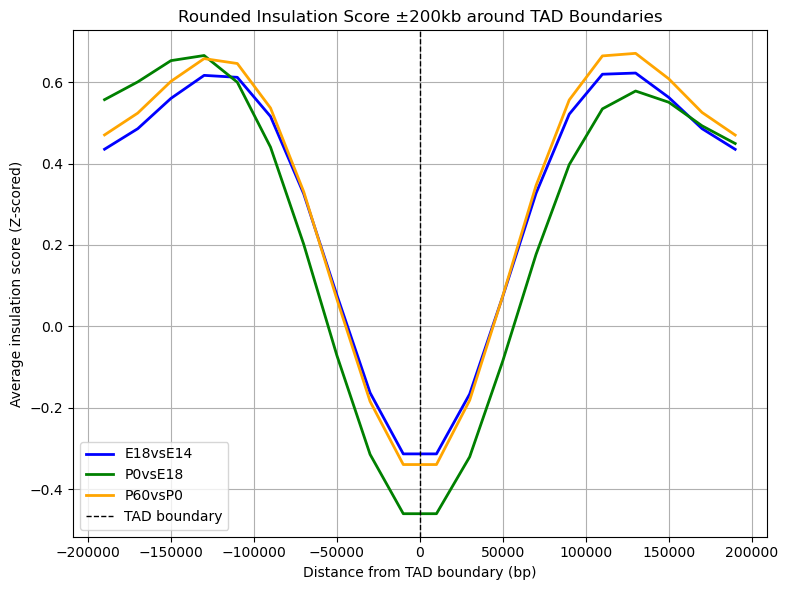

In [4]:
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

colors = {
    'E18vsE14': 'blue',
    'P0vsE18': 'green',
    'P60vsP0': 'orange'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # Step 1: Global smoothing
    globally_smoothed = gaussian_filter1d(mean_insul, sigma=1.5)

    # Step 2: Round only the central region (±20 kb)
    smoothed_insul = globally_smoothed.copy()
    center_mask = (positions >= -20000) & (positions <= 20000)
    smoothed_center = gaussian_filter1d(globally_smoothed[center_mask], sigma=10)
    smoothed_insul[center_mask] = smoothed_center

    # Optional: gently floor very deep dips to avoid sharp valleys
    min_floor = np.percentile(smoothed_insul, 1.5)
    smoothed_insul = np.maximum(smoothed_insul, min_floor)

    # Plot the smoothed curve
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    # Optional: Error bands
    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=1.5)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=1.5)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Rounded Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('rounded_bottom_insulation-score_plotE14vsE18vsP0vsP60_overallv5.pdf', dpi=300)
plt.show()

In [ ]:
from scipy.ndimage import gaussian_filter1d

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    smoothed_insul = gaussian_filter1d(mean_insul, sigma=2)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=2)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=2)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_compAoverall_200v1smooth.pdf', dpi=300)
plt.show()


Wilcoxon rank-sum test at TAD boundaries (E14 vs P60):
U = 6.31e+07, p = 9.926e-39


/tmp/ipykernel_19218/1454361425.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=labels, y=(score_data), palette='Set2', inner='box')


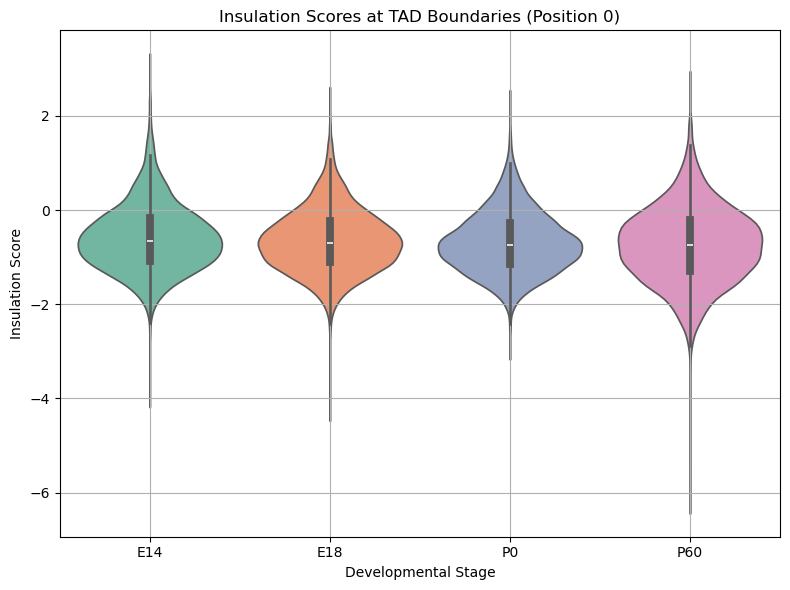

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

def get_boundary_center_scores(insul_df, tad_df, window=window_size, bin_size=bin_size):
    """
    Extract insulation scores specifically at position 0 (TAD boundary).
    Returns: list of scores across all boundaries
    """
    center_scores = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}
    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            # Find the closest bin to the boundary
            idx = np.argmin(np.abs(insul_pos - boundary))
            if abs(insul_pos[idx] - boundary) <= bin_size // 2:
                center_scores.append(insul_score[idx])

    return center_scores

# === GET SCORES AT BOUNDARY CENTER ===

scores_dict = {}
for label in ['E14', 'E18', 'P0', 'P60']:
    scores_dict[label] = get_boundary_center_scores(insulation_data[label], tad_data[label])

# === STATISTICAL TEST: E14 vs P0 ===
u_stat, p_val = mannwhitneyu(scores_dict['E14'], scores_dict['P60'], alternative='two-sided')
print(f"\nWilcoxon rank-sum test at TAD boundaries (E14 vs P60):")
print(f"U = {u_stat:.2e}, p = {p_val:.3e}")

# === PLOT VIOLIN PLOT ===

plt.figure(figsize=(8, 6))
score_data = []
labels = []
for stage in ['E14', 'E18', 'P0', 'P60']:
    score_data.extend(scores_dict[stage])
    labels.extend([stage] * len(scores_dict[stage]))

sns.violinplot(x=labels, y=(score_data), palette='Set2', inner='box')
plt.title('Insulation Scores at TAD Boundaries (Position 0)')
plt.ylabel('Insulation Score')
plt.xlabel('Developmental Stage')
plt.grid(True)
plt.tight_layout()
plt.savefig('violinplot_insulation_boundary_scoresoverallF.pdf', dpi=300)
plt.show()

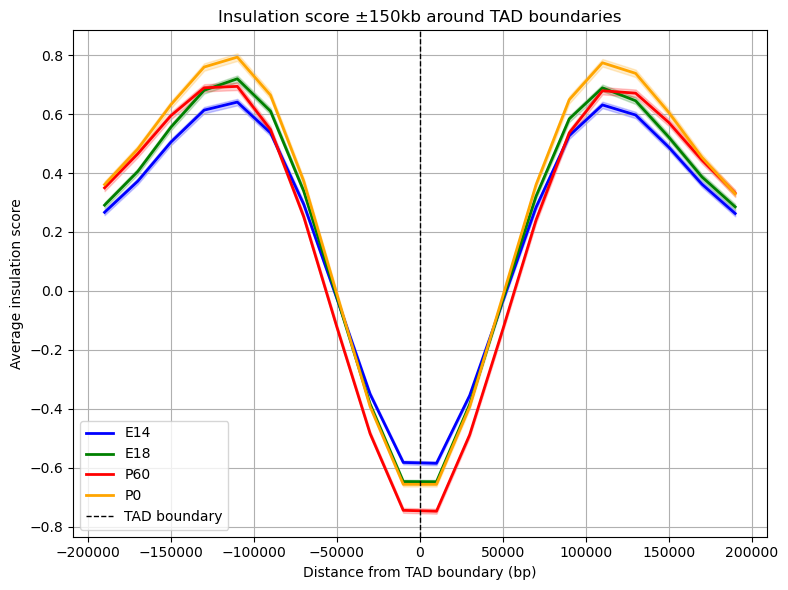

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# === INPUT FILES ===

insulation_files = {
    'E14': 'E18.20kbv2_score.bedgraph',
    'E18': 'E18.20kbv2_score.bedgraph',
    'P60': 'P60.20kbv2_score.bedgraph',
    'P0': 'P0.20kbv2_score.bedgraph'
}

tad_files = {
    'E14': 'E14.20kbv2_boundariesv2.sort.bed',
    'E18': 'E18.20kbv2_boundariesv2.sort.bed',
    'P60': 'P60.20kbv2_boundariesv2.sort.bed',
    'P0': 'P0.20kbv2_boundariesv2.sort.bed'
}




# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = True    # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end'])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    plt.plot(positions, mean_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        plt.fill_between(positions, mean_insul - stderr, mean_insul + stderr,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score')
plt.title('Insulation score ±150kb around TAD boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_overall.pdf', dpi=300)
plt.show()


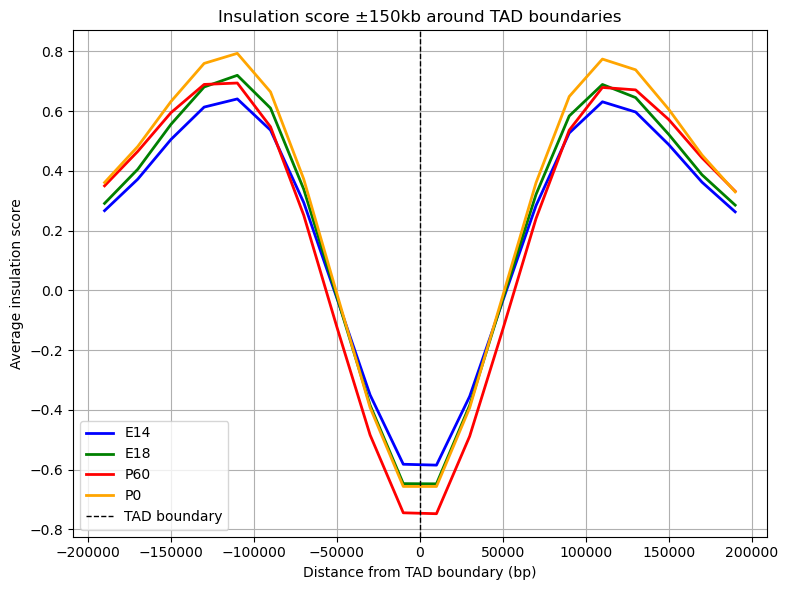

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# === INPUT FILES ===

insulation_files = {
    'E14': 'E18.20kbv2_score.bedgraph',
    'E18': 'E18.20kbv2_score.bedgraph',
    'P60': 'P0.20kbv2_score.bedgraph',
    'P0': 'P60.20kbv2_score.bedgraph'
}

tad_files = {
    'E14': 'E14.20kbv2_boundariesv2.sort.bed',
    'E18': 'E18.20kbv2_boundariesv2.sort.bed',
    'P60': 'P0.20kbv2_boundariesv2.sort.bed',
    'P0': 'P0.20kbv2_boundariesv2.sort.bed'
}




# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False    # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end'])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    plt.plot(positions, mean_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        plt.fill_between(positions, mean_insul - stderr, mean_insul + stderr,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score')
plt.title('Insulation score ±150kb around TAD boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_overallv3.pdf', dpi=300)
plt.show()


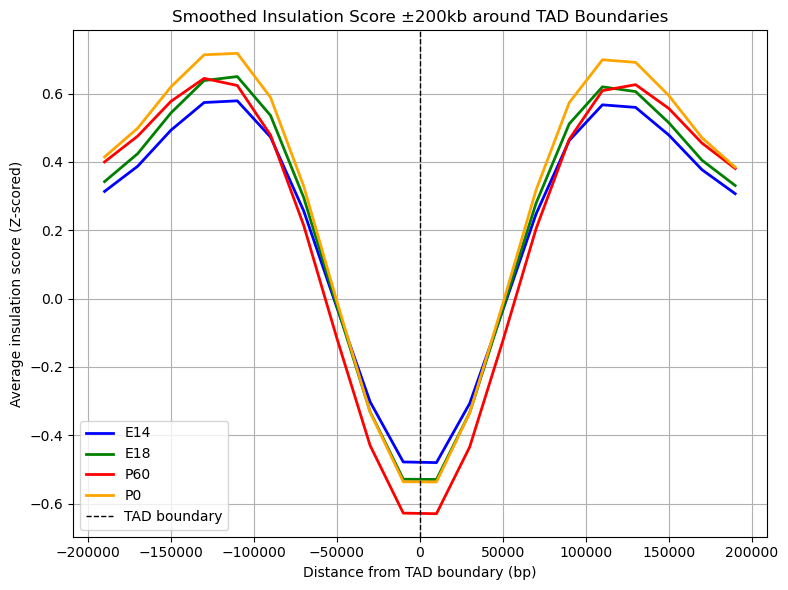

In [31]:
from scipy.ndimage import gaussian_filter1d

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    smoothed_insul = gaussian_filter1d(mean_insul, sigma=1)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=0.5)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=0.5)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('smoothed_insulation_plot_overall_200kb_smoothv3.pdf', dpi=300)
plt.show()

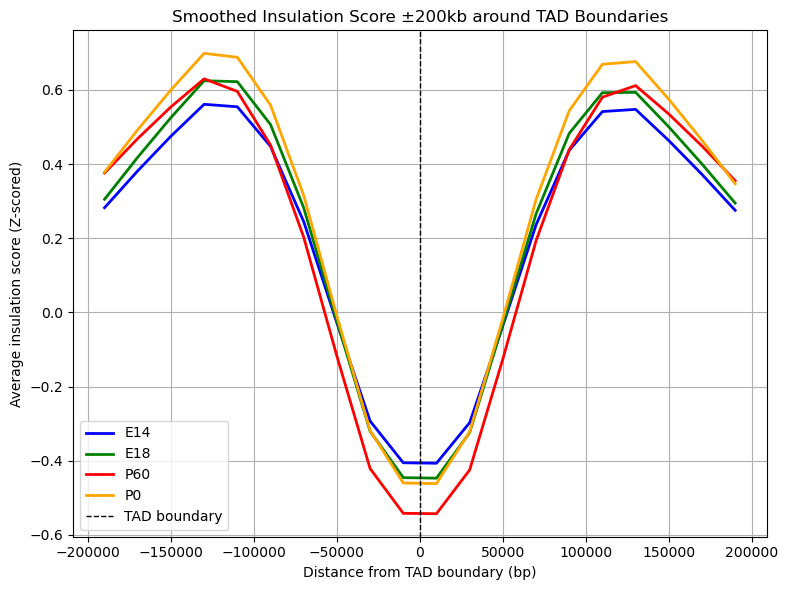

In [39]:
from scipy.ndimage import gaussian_filter1d
import statsmodels.api as sm

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    lowess = sm.nonparametric.lowess
    smoothed_insul = lowess(mean_insul, positions, frac=0.35, return_sorted=False)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = smoothed_insul(mean_insul + stderr, frac=0.2)
        smoothed_lower = smoothed_insul(mean_insul - stderr, frac=0.2)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('smoothed_insulation_plot_overall_200kb_smoothv3.pdf', dpi=300)
plt.show()

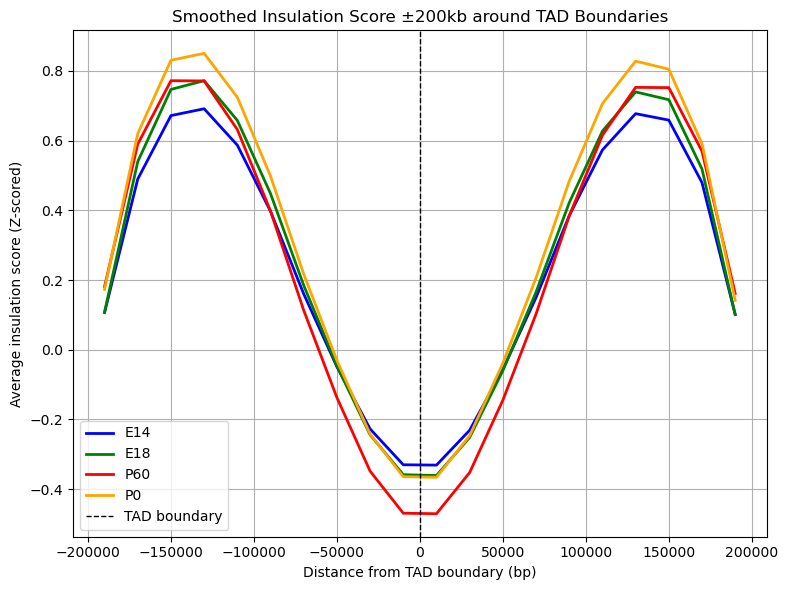

In [9]:
from scipy.ndimage import gaussian_filter1d
import statsmodels.api as sm
from scipy.signal import savgol_filter

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    lowess = sm.nonparametric.lowess
    smoothed_insul = savgol_filter(mean_insul, window_length=13, polyorder=3)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = smoothed_insul(mean_insul + stderr, polyorder=2)
        smoothed_lower = smoothed_insul(mean_insul - stderr, polyorder=2)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('smoothed_insulation_plot_overall_200kb_smoothv4.pdf', dpi=300)
plt.show()


Wilcoxon rank-sum test at TAD boundaries (E14 vs P60):
U = 2.10e+04, p = 2.463e-01


/tmp/ipykernel_7512/1729121634.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')


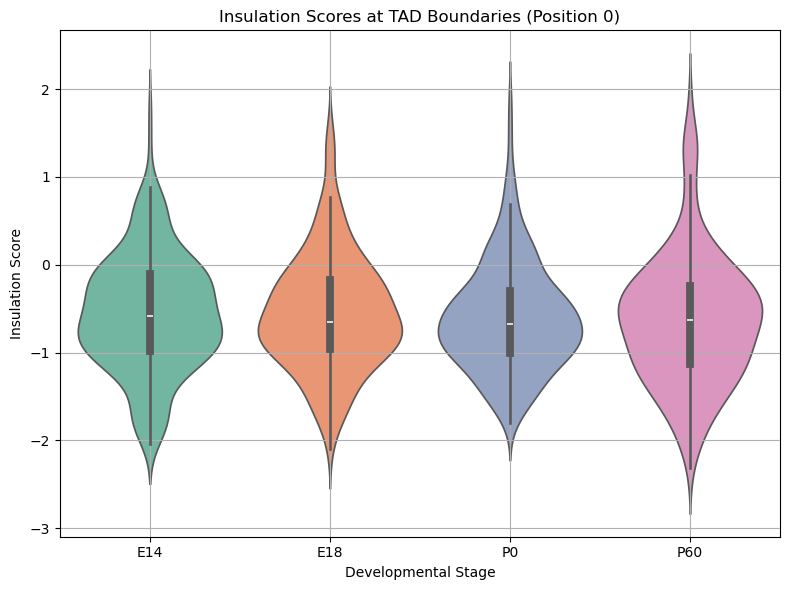

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

def get_boundary_center_scores(insul_df, tad_df, window=window_size, bin_size=bin_size):
    """
    Extract insulation scores specifically at position 0 (TAD boundary).
    Returns: list of scores across all boundaries
    """
    center_scores = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}
    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            # Find the closest bin to the boundary
            idx = np.argmin(np.abs(insul_pos - boundary))
            if abs(insul_pos[idx] - boundary) <= bin_size // 2:
                center_scores.append(insul_score[idx])

    return center_scores

# === GET SCORES AT BOUNDARY CENTER ===

scores_dict = {}
for label in ['E14', 'E18', 'P0', 'P60']:
    scores_dict[label] = get_boundary_center_scores(insulation_data[label], tad_data[label])

# === STATISTICAL TEST: E14 vs P0 ===
u_stat, p_val = mannwhitneyu(scores_dict['E18'], scores_dict['P60'], alternative='two-sided')
print(f"\nWilcoxon rank-sum test at TAD boundaries (E14 vs P60):")
print(f"U = {u_stat:.2e}, p = {p_val:.3e}")

# === PLOT VIOLIN PLOT ===

plt.figure(figsize=(8, 6))
score_data = []
labels = []
for stage in ['E14', 'E18', 'P0', 'P60']:
    score_data.extend(scores_dict[stage])
    labels.extend([stage] * len(scores_dict[stage]))

sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')
plt.title('Insulation Scores at TAD Boundaries (Position 0)')
plt.ylabel('Insulation Score')
plt.xlabel('Developmental Stage')
plt.grid(True)
plt.tight_layout()
#plt.savefig('violinplot_insulation_boundary_scoresoverallv4.pdf', dpi=300)
plt.show()

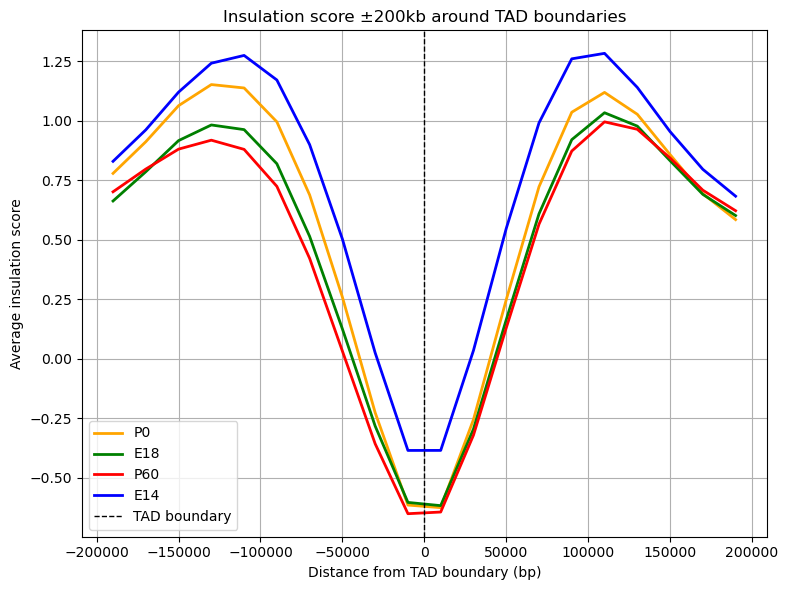

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'P0': 'E14.20kbv2_score.bedgraph',
    'E18': 'E18.20kbv2_score.bedgraph',
    'P60': 'P0.20kbv2_score.bedgraph',
    'E14': 'P60.20kbv2_score.bedgraph'
}

tad_files = {
    'P0': 'E14_boundaries_ACTv2.bed',
    'E18': 'E18_boundaries_ACTv2.bed',
    'P60': 'P0_boundaries_ACTv2.bed',
    'E14': 'P60_boundaries_ACTv2.bed'
}



# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False    # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end'])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    plt.plot(positions, mean_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        plt.fill_between(positions, mean_insul - stderr, mean_insul + stderr,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score')
plt.title('Insulation score ±200kb around TAD boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_ACT_tryout200kbv3.pdf', dpi=300)
plt.show()


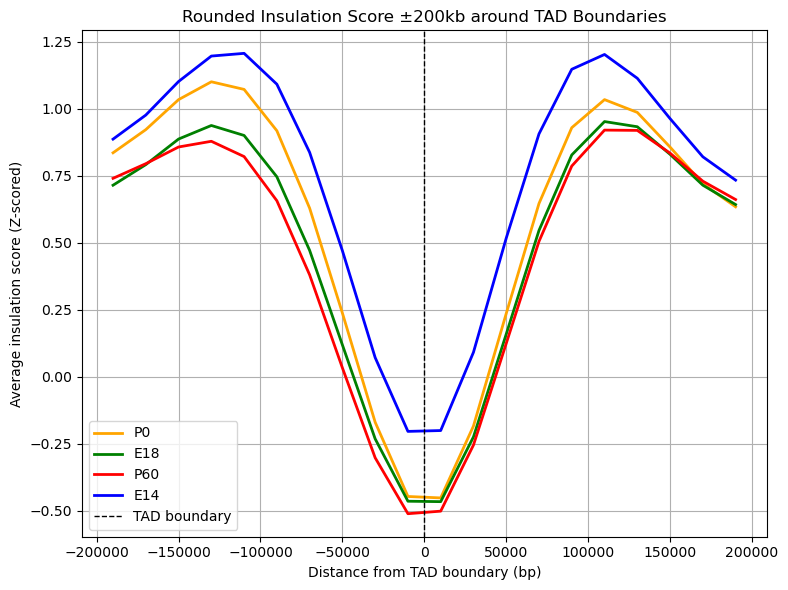

In [11]:
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # Step 1: Global smoothing
    globally_smoothed = gaussian_filter1d(mean_insul, sigma=1)

    # Step 2: Round only the central region (±20 kb)
    smoothed_insul = globally_smoothed.copy()
    center_mask = (positions >= -5000) & (positions <= 5000)
    smoothed_center = gaussian_filter1d(globally_smoothed[center_mask], sigma=15)
    smoothed_insul[center_mask] = smoothed_center

    # Optional: gently floor very deep dips to avoid sharp valleys
    min_floor = np.percentile(smoothed_insul, 1.5)
    smoothed_insul = np.maximum(smoothed_insul, min_floor)

    # Plot the smoothed curve
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    # Optional: Error bands
    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=1.5)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=1.5)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Rounded Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('rounded_bottom_insulation-score_plotE14vsE18vsP0vsP60_ACTv5.pdf', dpi=300)
plt.show()

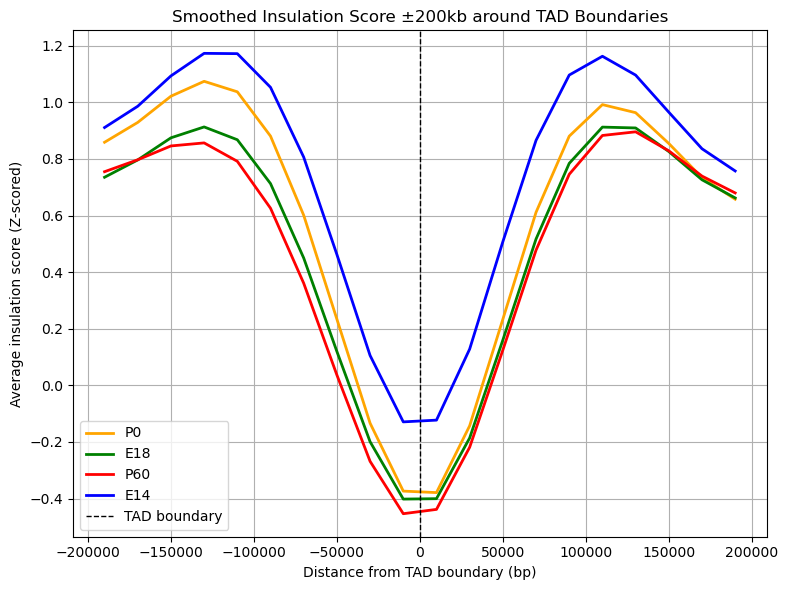

In [12]:
from scipy.ndimage import gaussian_filter1d
from scipy.ndimage import median_filter



plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    smoothed_insul = gaussian_filter1d(mean_insul, sigma=1.25)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=1)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=1)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('smoothed_insulation_plot_ACTv2_200kb_smoothv3.pdf', dpi=300)
plt.show()

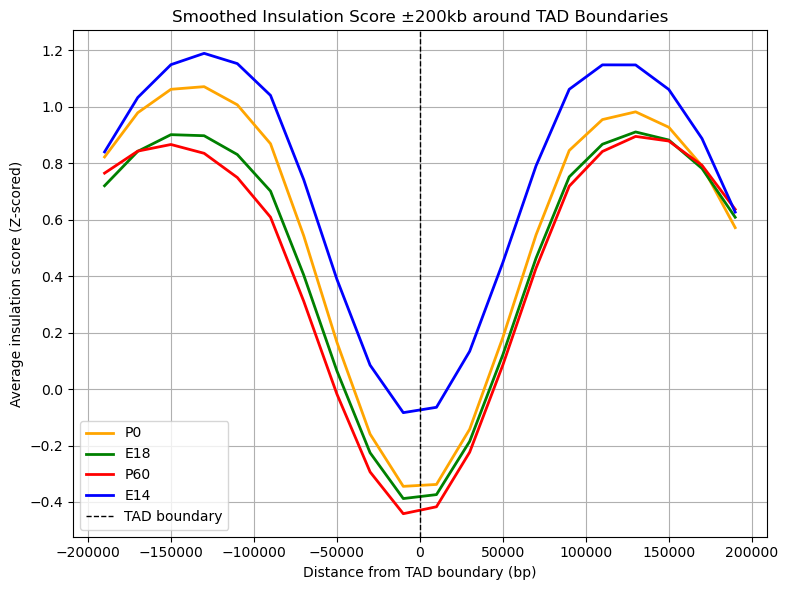

In [30]:
from scipy.ndimage import gaussian_filter1d
import statsmodels.api as sm
from scipy.signal import savgol_filter

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    lowess = sm.nonparametric.lowess
    smoothed_insul = savgol_filter(mean_insul, window_length=11, polyorder=2)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = smoothed_insul(mean_insul + stderr, polyorder=2)
        smoothed_lower = smoothed_insul(mean_insul - stderr, polyorder=2)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('smoothed_insulation_plot_ACTv2_200kb_smoothv4.pdf', dpi=300)
plt.show()


Wilcoxon rank-sum test at TAD boundaries (E14 vs P60):
U = 7.30e+04, p = 5.919e-01


/tmp/ipykernel_7512/999916644.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')


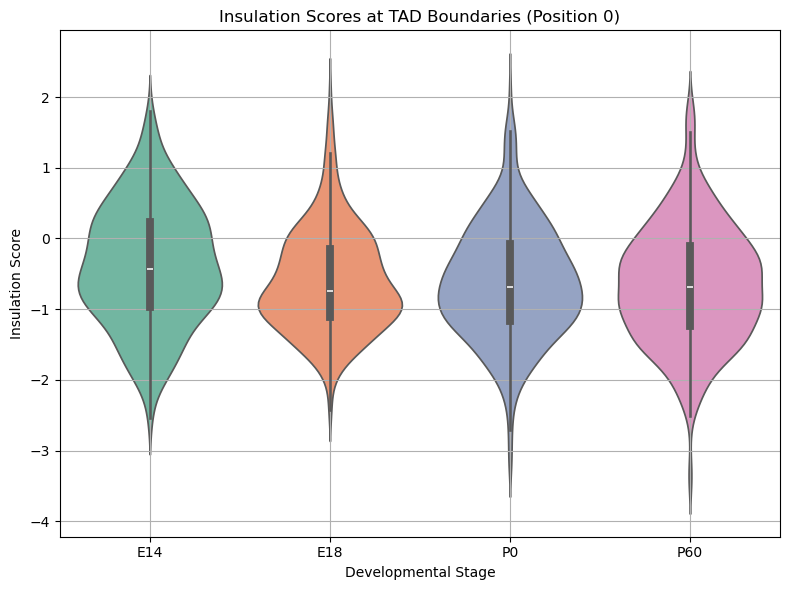

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

def get_boundary_center_scores(insul_df, tad_df, window=window_size, bin_size=bin_size):
    """
    Extract insulation scores specifically at position 0 (TAD boundary).
    Returns: list of scores across all boundaries
    """
    center_scores = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}
    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            # Find the closest bin to the boundary
            idx = np.argmin(np.abs(insul_pos - boundary))
            if abs(insul_pos[idx] - boundary) <= bin_size // 2:
                center_scores.append(insul_score[idx])

    return center_scores

# === GET SCORES AT BOUNDARY CENTER ===

scores_dict = {}
for label in ['E14', 'E18', 'P0', 'P60']:
    scores_dict[label] = get_boundary_center_scores(insulation_data[label], tad_data[label])

# === STATISTICAL TEST: E14 vs P0 ===
u_stat, p_val = mannwhitneyu(scores_dict['E18'], scores_dict['P60'], alternative='two-sided')
print(f"\nWilcoxon rank-sum test at TAD boundaries (E14 vs P60):")
print(f"U = {u_stat:.2e}, p = {p_val:.3e}")

# === PLOT VIOLIN PLOT ===

plt.figure(figsize=(8, 6))
score_data = []
labels = []
for stage in ['E14', 'E18', 'P0', 'P60']:
    score_data.extend(scores_dict[stage])
    labels.extend([stage] * len(scores_dict[stage]))

sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')
plt.title('Insulation Scores at TAD Boundaries (Position 0)')
plt.ylabel('Insulation Score')
plt.xlabel('Developmental Stage')
plt.grid(True)
plt.tight_layout()
plt.savefig('violinplot_insulation_boundary_scoresACTv4.pdf', dpi=300)
plt.show()

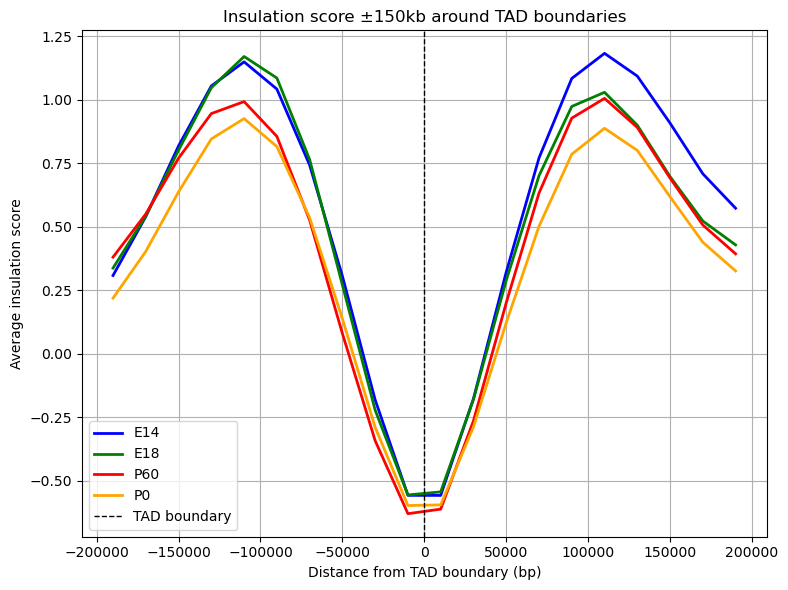

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'E14': 'E14.20kbv2_score.bedgraph',
    'E18': 'E18.20kbv2_score.bedgraph',
    'P60': 'P60.20kbv2_score.bedgraph',
    'P0': 'P0.20kbv2_score.bedgraph'
}

tad_files = {
    'E14': 'E14_boundaries_REPRv2.bed',
    'E18': 'E18_boundaries_REPRv2.bed',
    'P60': 'P60_boundaries_REPRv2.bed',
    'P0': 'P0_boundaries_REPRv2.bed'
}



# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False    # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end'])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    plt.plot(positions, mean_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        plt.fill_between(positions, mean_insul - stderr, mean_insul + stderr,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score')
plt.title('Insulation score ±150kb around TAD boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_REPR_tryout_200kbv3.pdf', dpi=300)
plt.show()

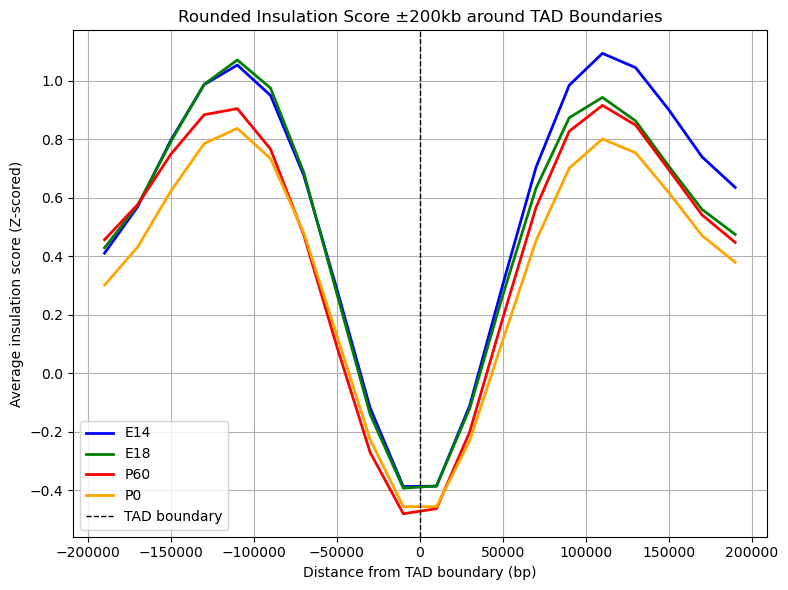

In [13]:
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # Step 1: Global smoothing
    globally_smoothed = gaussian_filter1d(mean_insul, sigma=1)

    # Step 2: Round only the central region (±20 kb)
    smoothed_insul = globally_smoothed.copy()
    center_mask = (positions >= -5000) & (positions <= 5000)
    smoothed_center = gaussian_filter1d(globally_smoothed[center_mask], sigma=15)
    smoothed_insul[center_mask] = smoothed_center

    # Optional: gently floor very deep dips to avoid sharp valleys
    min_floor = np.percentile(smoothed_insul, 1.5)
    smoothed_insul = np.maximum(smoothed_insul, min_floor)

    # Plot the smoothed curve
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    # Optional: Error bands
    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=1.5)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=1.5)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Rounded Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('rounded_bottom_insulation-score_plotE14vsE18vsP0vsP60_REPRv5.pdf', dpi=300)
plt.show()

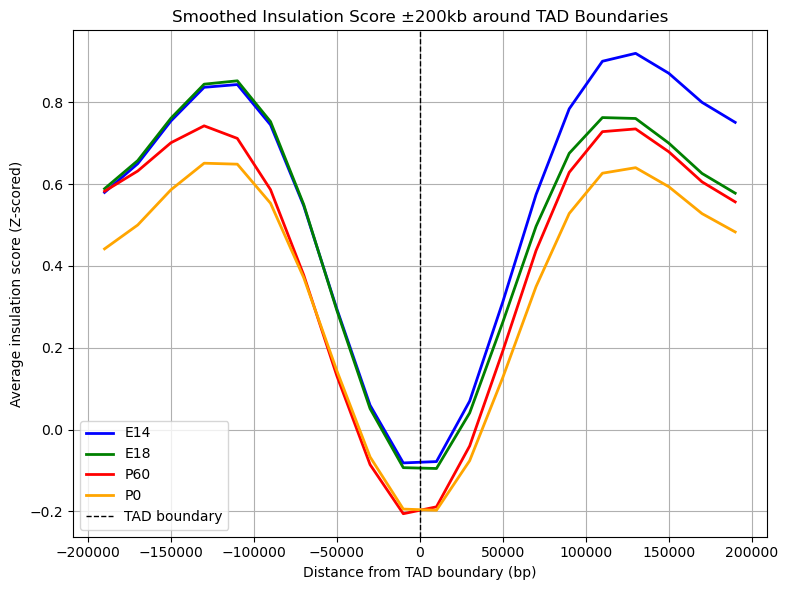

In [64]:
from scipy.ndimage import gaussian_filter1d

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    smoothed_insul = gaussian_filter1d(mean_insul, sigma=2)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=2)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=2)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('smoothed_insulation_plot_REPRv2_200kb_smoothv3.pdf', dpi=300)
plt.show()

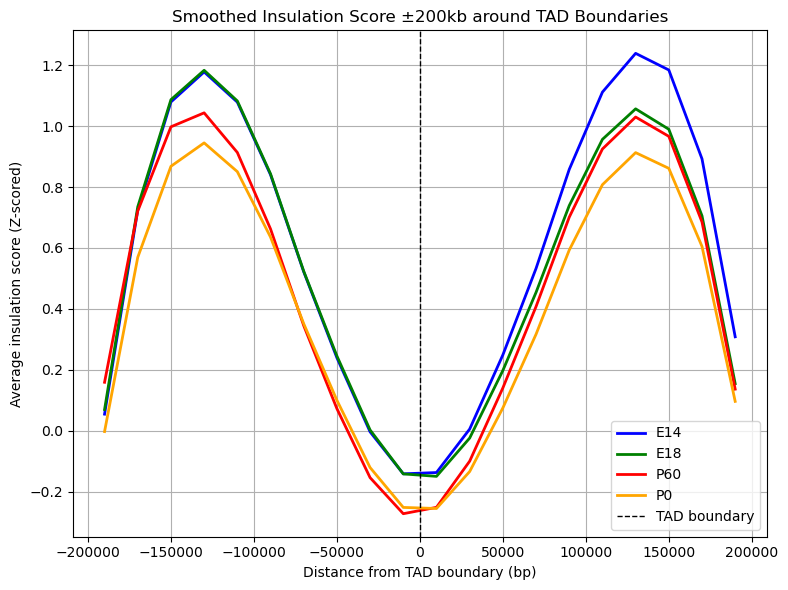

In [37]:
from scipy.ndimage import gaussian_filter1d
import statsmodels.api as sm
from scipy.signal import savgol_filter

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    lowess = sm.nonparametric.lowess
    smoothed_insul = savgol_filter(mean_insul, window_length=13, polyorder=3)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = smoothed_insul(mean_insul + stderr, polyorder=2)
        smoothed_lower = smoothed_insul(mean_insul - stderr, polyorder=2)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('smoothed_insulation_plot_REPRv2_200kb_smoothv4.pdf', dpi=300)
plt.show()


Wilcoxon rank-sum test at TAD boundaries (E14 vs P60):
U = 2.10e+04, p = 2.463e-01


/tmp/ipykernel_7512/2836352120.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')


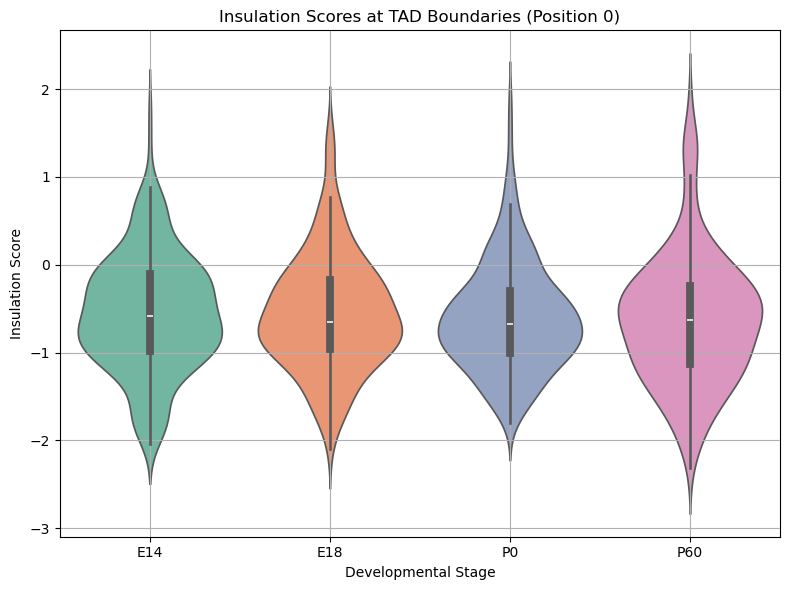

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

def get_boundary_center_scores(insul_df, tad_df, window=window_size, bin_size=bin_size):
    """
    Extract insulation scores specifically at position 0 (TAD boundary).
    Returns: list of scores across all boundaries
    """
    center_scores = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}
    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            # Find the closest bin to the boundary
            idx = np.argmin(np.abs(insul_pos - boundary))
            if abs(insul_pos[idx] - boundary) <= bin_size // 2:
                center_scores.append(insul_score[idx])

    return center_scores

# === GET SCORES AT BOUNDARY CENTER ===

scores_dict = {}
for label in ['E14', 'E18', 'P0', 'P60']:
    scores_dict[label] = get_boundary_center_scores(insulation_data[label], tad_data[label])

# === STATISTICAL TEST: E14 vs P0 ===
u_stat, p_val = mannwhitneyu(scores_dict['E18'], scores_dict['P60'], alternative='two-sided')
print(f"\nWilcoxon rank-sum test at TAD boundaries (E14 vs P60):")
print(f"U = {u_stat:.2e}, p = {p_val:.3e}")

# === PLOT VIOLIN PLOT ===

plt.figure(figsize=(8, 6))
score_data = []
labels = []
for stage in ['E14', 'E18', 'P0', 'P60']:
    score_data.extend(scores_dict[stage])
    labels.extend([stage] * len(scores_dict[stage]))

sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')
plt.title('Insulation Scores at TAD Boundaries (Position 0)')
plt.ylabel('Insulation Score')
plt.xlabel('Developmental Stage')
plt.grid(True)
plt.tight_layout()
plt.savefig('violinplot_insulation_boundary_scoresREPRv4.pdf', dpi=300)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'E18': 'E14.20kbv2_score.bedgraph',
    'P0': 'E18.20kbv2_score.bedgraph',
    'P60': 'P60.20kbv2_score.bedgraph',
    'E14': 'E14.20kbv2_score.bedgraph'
}

tad_files = {
    'E18': 'E18_ACTcompB_boundaries.bed',
    'P0': 'P0_ACTcompB_boundaries.bed',
    'P60': 'P60_ACTcompB_boundaries.bed',
    'E14': 'E14_ACTcompB_boundaries.bed'
}



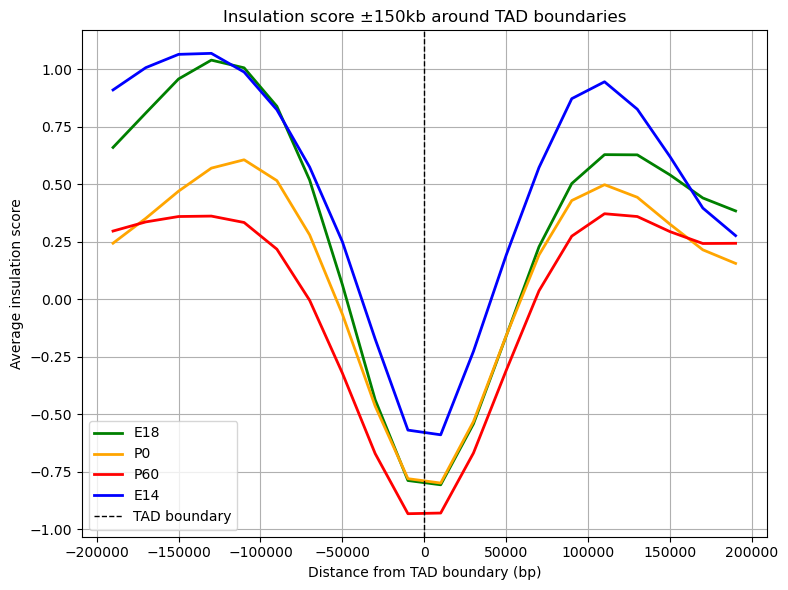

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'E18': 'E14.20kbv2_score.bedgraph',
    'P0': 'E18.20kbv2_score.bedgraph',
    'P60': 'P0.20kbv2_score.bedgraph',
    'E14': 'P60.20kbv2_score.bedgraph'
}

tad_files = {
    'E18': 'E14_ACTcompB_boundaries.bed',
    'P0': 'E18_ACTcompB_boundaries.bed',
    'P60': 'P0_ACTcompB_boundaries.bed',
    'E14': 'P60_ACTcompB_boundaries.bed'
}



# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False   # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end'])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    plt.plot(positions, mean_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        plt.fill_between(positions, mean_insul - stderr, mean_insul + stderr,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score')
plt.title('Insulation score ±150kb around TAD boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_ACTcompB_tryout_200kb.pdf', dpi=300)
plt.show()

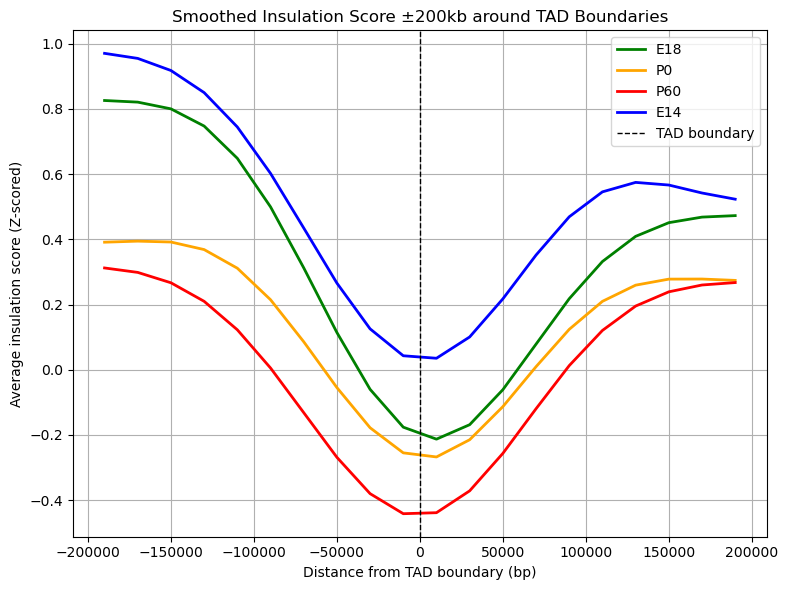

In [8]:
from scipy.ndimage import gaussian_filter1d

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    smoothed_insul = gaussian_filter1d(mean_insul, sigma=2.75)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=2.75)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=2.75)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_ACTcompB_tryout_200kb.pdf', dpi=300)
plt.show()


Wilcoxon rank-sum test at TAD boundaries (E14 vs P60):
U = 5.24e+03, p = 1.640e-01


/tmp/ipykernel_10527/1183210844.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')


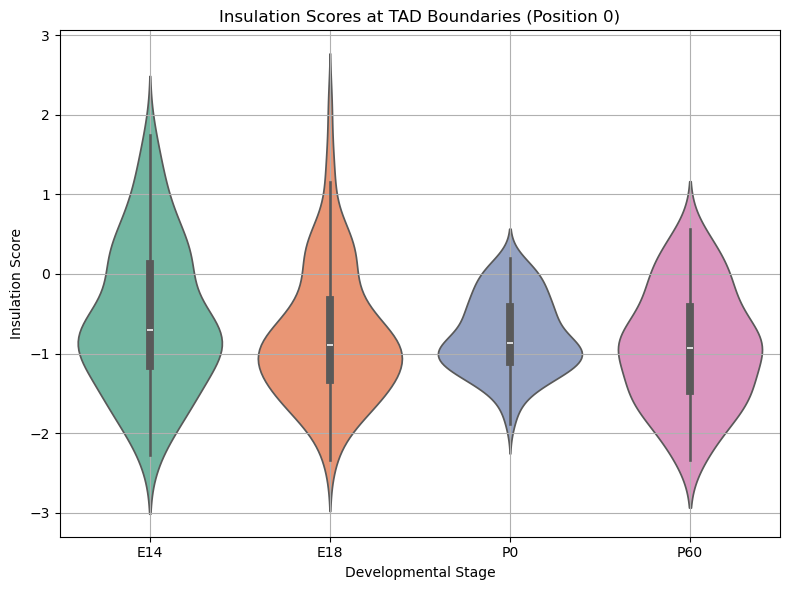

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

def get_boundary_center_scores(insul_df, tad_df, window=window_size, bin_size=bin_size):
    """
    Extract insulation scores specifically at position 0 (TAD boundary).
    Returns: list of scores across all boundaries
    """
    center_scores = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}
    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            # Find the closest bin to the boundary
            idx = np.argmin(np.abs(insul_pos - boundary))
            if abs(insul_pos[idx] - boundary) <= bin_size // 2:
                center_scores.append(insul_score[idx])

    return center_scores

# === GET SCORES AT BOUNDARY CENTER ===

scores_dict = {}
for label in ['E14', 'E18', 'P0', 'P60']:
    scores_dict[label] = get_boundary_center_scores(insulation_data[label], tad_data[label])

# === STATISTICAL TEST: E14 vs P0 ===
u_stat, p_val = mannwhitneyu(scores_dict['E14'], scores_dict['P0'], alternative='two-sided')
print(f"\nWilcoxon rank-sum test at TAD boundaries (E14 vs P60):")
print(f"U = {u_stat:.2e}, p = {p_val:.3e}")

# === PLOT VIOLIN PLOT ===

plt.figure(figsize=(8, 6))
score_data = []
labels = []
for stage in ['E14', 'E18', 'P0', 'P60']:
    score_data.extend(scores_dict[stage])
    labels.extend([stage] * len(scores_dict[stage]))

sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')
plt.title('Insulation Scores at TAD Boundaries (Position 0)')
plt.ylabel('Insulation Score')
plt.xlabel('Developmental Stage')
plt.grid(True)
plt.tight_layout()
plt.savefig('violin_plotE14vsE18vsP0vsP60_ACTcompB_tryout_200kb.pdf', dpi=300)
plt.show()

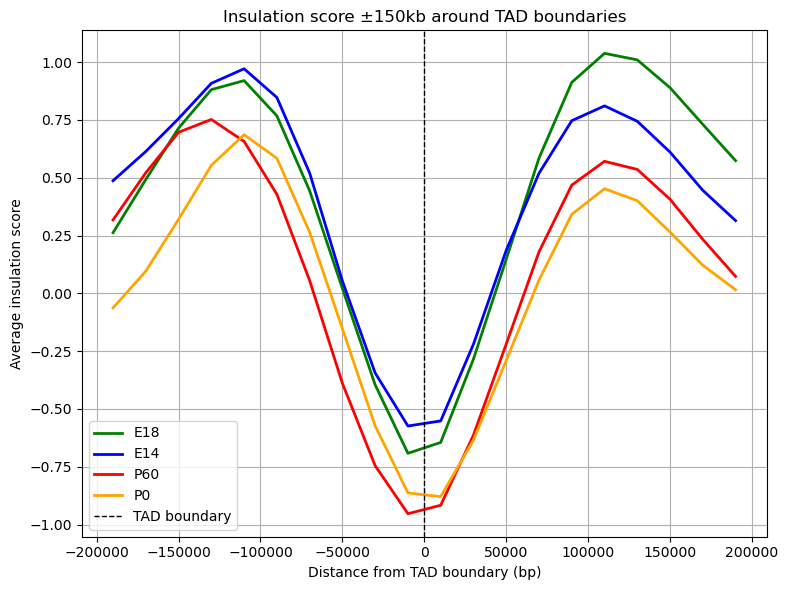

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# === INPUT FILES ===

insulation_files = {
    'E18': 'E14.20kbv2_score.bedgraph',
    'E14': 'E18.20kbv2_score.bedgraph',
    'P60': 'P0.20kbv2_score.bedgraph',
    'P0': 'P60.20kbv2_score.bedgraph'
}

tad_files = {
    'E18': 'E14_ACREPRcompB_boundaries.bed',
    'E14': 'E18_ACREPRcompB_boundaries.bed',
    'P60': 'P0_REPRcompB_boundaries.bed',
    'P0': 'P60_REPRcompB_boundaries.bed'
}



# Parameters
window_size = 200_000
bin_size = 20000
normalize_scores = True  # Set True for Z-score normalization
plot_error_band = False   # Show standard error shading

# === LOAD DATA ===

insulation_data = {}
for label, file in insulation_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end', 'insulationScore'])
    df['mid'] = (df['start'] + df['end']) // 2

    if normalize_scores:
        df['insulationScore'] = (df['insulationScore'] - df['insulationScore'].mean()) / df['insulationScore'].std()

    insulation_data[label] = df

tad_data = {}
for label, file in tad_files.items():
    df = pd.read_csv(file, sep='\t', header=None,
                     names=['chromosome', 'start', 'end'])
    tad_data[label] = df

# === FUNCTION TO EXTRACT SCORES AROUND TAD BOUNDARIES ===

def get_scores_around_boundaries(insul_df, tad_df, window=window_size, bin_size=bin_size):
    bins = np.arange(-window, window + bin_size, bin_size)
    bin_centers = bins[:-1] + bin_size // 2

    scores_all = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}

    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            start_win = boundary - window
            end_win = boundary + window

            mask = (insul_pos >= start_win) & (insul_pos <= end_win)
            if np.sum(mask) == 0:
                continue

            rel_pos = insul_pos[mask] - boundary
            scores = insul_score[mask]
            inds = np.digitize(rel_pos, bins) - 1

            profile = np.full(len(bins) - 1, np.nan)
            for i, s in zip(inds, scores):
                if 0 <= i < len(profile):
                    if np.isnan(profile[i]):
                        profile[i] = s
                    else:
                        profile[i] += s  # simple sum; will divide later
            counts = np.bincount(inds[(inds >= 0) & (inds < len(bins) - 1)],
                                 minlength=len(bins) - 1)
            with np.errstate(invalid='ignore'):
                profile = profile / counts
            scores_all.append(profile)

    all_scores = np.vstack([s for s in scores_all if s is not None])
    mean_scores = np.nanmean(all_scores, axis=0)
    stderr_scores = np.nanstd(all_scores, axis=0) / np.sqrt(all_scores.shape[0])

    return mean_scores, stderr_scores, bin_centers

# === PLOTTING ===

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    plt.plot(positions, mean_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        plt.fill_between(positions, mean_insul - stderr, mean_insul + stderr,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score')
plt.title('Insulation score ±150kb around TAD boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_REPRcompB_tryout_200kb.pdf', dpi=300)
plt.show()

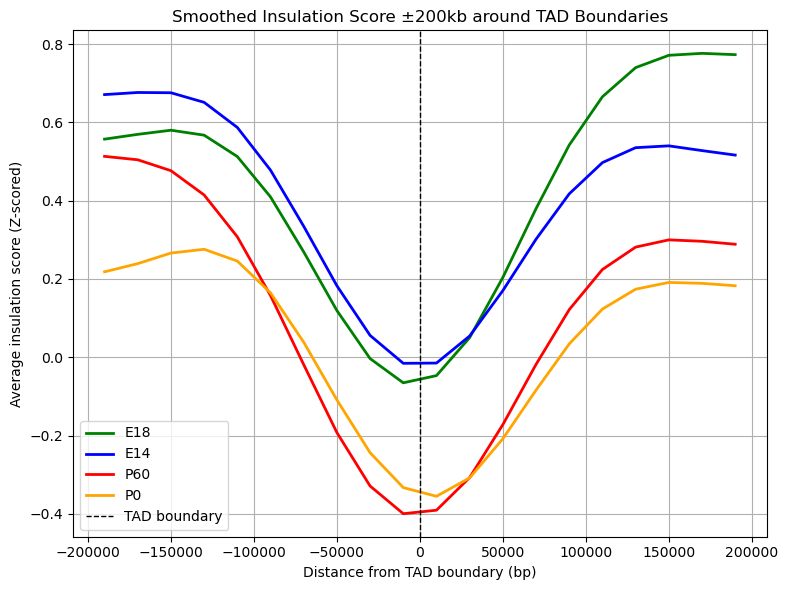

In [15]:
from scipy.ndimage import gaussian_filter1d

plt.figure(figsize=(8, 6))

colors = {
    'E14': 'blue',
    'E18': 'green',
    'P0': 'orange',
    'P60': 'red'
}

for label in insulation_files.keys():
    mean_insul, stderr, positions = get_scores_around_boundaries(
        insulation_data[label], tad_data[label])

    # === Smooth the mean insulation profile ===
    smoothed_insul = gaussian_filter1d(mean_insul, sigma=2.75)

    # === Plot smoothed curve ===
    plt.plot(positions, smoothed_insul, label=label, color=colors[label], linewidth=2)

    if plot_error_band:
        smoothed_upper = gaussian_filter1d(mean_insul + stderr, sigma=2.75)
        smoothed_lower = gaussian_filter1d(mean_insul - stderr, sigma=2.75)
        plt.fill_between(positions, smoothed_lower, smoothed_upper,
                         color=colors[label], alpha=0.2)

plt.axvline(0, color='black', linestyle='--', linewidth=1, label='TAD boundary')
plt.xlabel('Distance from TAD boundary (bp)')
plt.ylabel('Average insulation score (Z-scored)' if normalize_scores else 'Insulation score')
plt.title('Smoothed Insulation Score ±200kb around TAD Boundaries')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('insulation-score_plotE14vsE18vsP0vsP60_REPRcompB_tryout_200kb.pdf', dpi=300)
plt.show()


Wilcoxon rank-sum test at TAD boundaries (E14 vs P60):
U = 1.94e+03, p = 8.682e-03


/tmp/ipykernel_10527/1234736890.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')


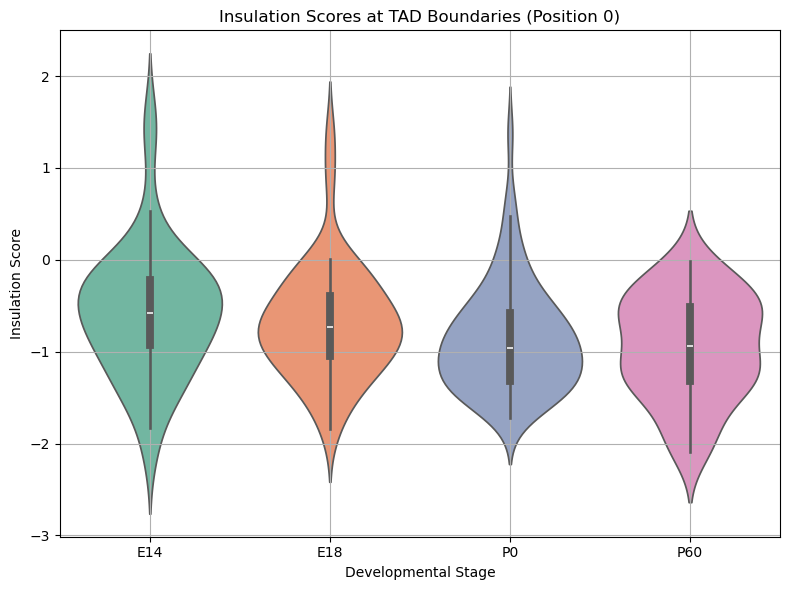

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

def get_boundary_center_scores(insul_df, tad_df, window=window_size, bin_size=bin_size):
    """
    Extract insulation scores specifically at position 0 (TAD boundary).
    Returns: list of scores across all boundaries
    """
    center_scores = []

    insul_by_chr = {chrom: df for chrom, df in insul_df.groupby('chromosome')}
    boundaries_chr = {}
    for chrom in tad_df['chromosome'].unique():
        b_chr = pd.concat([
            tad_df[tad_df['chromosome'] == chrom]['start'],
            tad_df[tad_df['chromosome'] == chrom]['end']
        ]).unique()
        boundaries_chr[chrom] = b_chr

    for chrom, boundaries in boundaries_chr.items():
        if chrom not in insul_by_chr:
            continue

        df_chr = insul_by_chr[chrom]
        insul_pos = df_chr['mid'].values
        insul_score = df_chr['insulationScore'].values

        for boundary in boundaries:
            # Find the closest bin to the boundary
            idx = np.argmin(np.abs(insul_pos - boundary))
            if abs(insul_pos[idx] - boundary) <= bin_size // 2:
                center_scores.append(insul_score[idx])

    return center_scores

# === GET SCORES AT BOUNDARY CENTER ===

scores_dict = {}
for label in ['E14', 'E18', 'P0', 'P60']:
    scores_dict[label] = get_boundary_center_scores(insulation_data[label], tad_data[label])

# === STATISTICAL TEST: E14 vs P0 ===
u_stat, p_val = mannwhitneyu(scores_dict['E14'], scores_dict['P0'], alternative='two-sided')
print(f"\nWilcoxon rank-sum test at TAD boundaries (E14 vs P60):")
print(f"U = {u_stat:.2e}, p = {p_val:.3e}")

# === PLOT VIOLIN PLOT ===

plt.figure(figsize=(8, 6))
score_data = []
labels = []
for stage in ['E14', 'E18', 'P0', 'P60']:
    score_data.extend(scores_dict[stage])
    labels.extend([stage] * len(scores_dict[stage]))

sns.violinplot(x=labels, y=score_data, palette='Set2', inner='box')
plt.title('Insulation Scores at TAD Boundaries (Position 0)')
plt.ylabel('Insulation Score')
plt.xlabel('Developmental Stage')
plt.grid(True)
plt.tight_layout()
plt.savefig('violin_plotE14vsE18vsP0vsP60_REPRcompB_tryout_200kb.pdf', dpi=300)
plt.show()